# Experiment 10: Complete Optimization System using GA with DEAP

**Aim:** To design and implement a complete optimization system using a Genetic Algorithm in Python with the DEAP library by integrating population initialization, fitness evaluation, selection, crossover, mutation and convergence analysis.

**Theory:** DEAP is an evolutionary computation library. A Toolbox registers the individual, population, evaluation, selection, crossover and mutation operators, and algorithms.eaSimple runs the GA. Problem: 0/1 Knapsack – select items to maximise total value without exceeding the weight capacity (infeasible solutions get fitness 0).

**Step 0:** Import the required libraries and fix the random seed.

In [1]:
import random, numpy as np
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42)

**Step 1:** Import DEAP and create the knapsack data.

In [2]:
from deap import base, creator, tools, algorithms
random.seed(7); np.random.seed(7)
N_ITEMS, CAPACITY = 20, 50
items = [(random.randint(1,10), random.randint(5,40)) for _ in range(N_ITEMS)]   # (weight, value)
print("Items (weight, value):", items)

Items (weight, value): [(6, 14), (7, 8), (2, 39), (2, 28), (10, 8), (9, 18), (1, 10), (7, 31), (2, 20), (2, 40), (7, 8), (10, 12), (4, 8), (10, 30), (1, 19), (1, 40), (3, 23), (7, 14), (9, 12), (10, 24)]


**Step 2:** Create the fitness and individual types.

In [3]:
creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

**Step 3:** Register population initialisation in the toolbox.

In [4]:
tb = base.Toolbox()
tb.register("attr_bool", random.randint, 0, 1)
tb.register("individual", tools.initRepeat, creator.Individual, tb.attr_bool, N_ITEMS)
tb.register("population", tools.initRepeat, list, tb.individual)

**Step 4:** Define and register the fitness evaluation, selection, crossover and mutation.

In [5]:
def eval_knap(ind):
    w = sum(i*it[0] for i, it in zip(ind, items)); v = sum(i*it[1] for i, it in zip(ind, items))
    return (0,) if w > CAPACITY else (v,)

tb.register("evaluate", eval_knap)
tb.register("select", tools.selTournament, tournsize=3)
tb.register("mate", tools.cxTwoPoint)
tb.register("mutate", tools.mutFlipBit, indpb=0.05)

**Step 5:** Create the population, statistics and Hall of Fame, then run the GA.

In [6]:
pop = tb.population(n=100)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("max", np.max); stats.register("avg", np.mean)
pop, log = algorithms.eaSimple(pop, tb, cxpb=0.7, mutpb=0.2, ngen=40, stats=stats, halloffame=hof, verbose=False)

**Step 6:** Display the best solution.

In [7]:
best = hof[0]
tw = sum(i*it[0] for i, it in zip(best, items)); tv = sum(i*it[1] for i, it in zip(best, items))
print("Best solution:", best)
print("Items chosen :", [k for k, b in enumerate(best) if b])
print(f"Total weight : {tw} / {CAPACITY}\nTotal value  : {tv}")

Best solution: [1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1]
Items chosen : [0, 2, 3, 6, 7, 8, 9, 13, 14, 15, 16, 19]
Total weight : 47 / 50
Total value  : 318


**Step 7:** Convergence analysis – plot max and average fitness per generation.

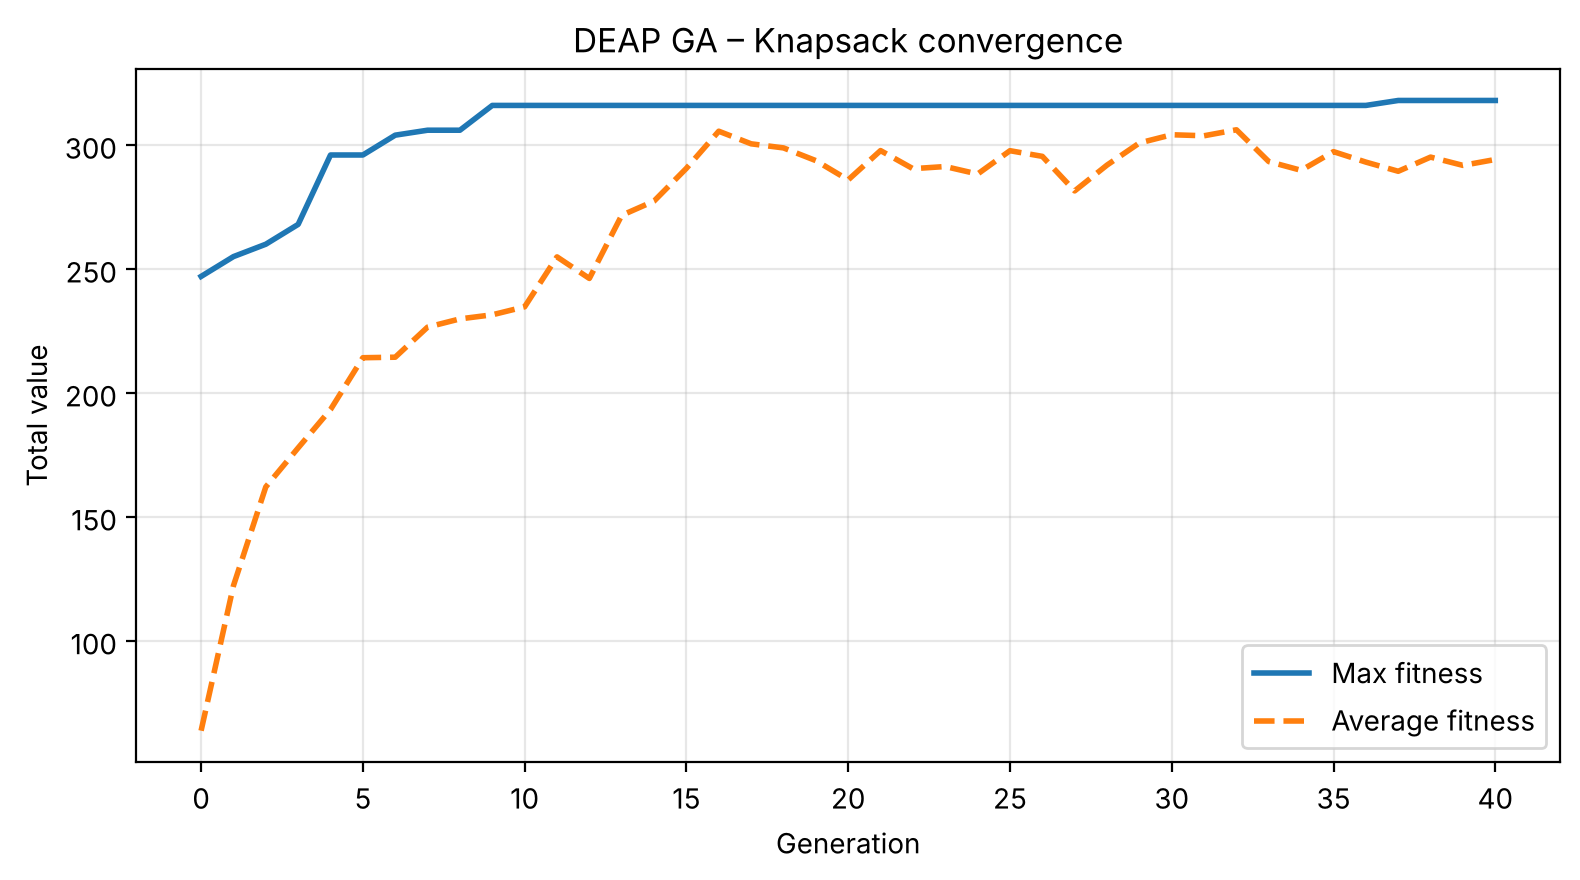

In [8]:
gen = log.select("gen"); mx = log.select("max"); av = log.select("avg")
plt.figure(figsize=(8,4.5))
plt.plot(gen, mx, lw=2, label="Max fitness"); plt.plot(gen, av, lw=2, ls="--", label="Average fitness")
plt.xlabel("Generation"); plt.ylabel("Total value"); plt.title("DEAP GA – Knapsack convergence")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

**Step 8:** Verify the result against the true optimum using dynamic programming.

In [9]:
dp = [0]*(CAPACITY+1)
for w_, v_ in items:
    for c in range(CAPACITY, w_-1, -1): dp[c] = max(dp[c], dp[c-w_]+v_)
print("Optimal value (DP check):", dp[CAPACITY])

Optimal value (DP check): 322
